In [2]:
pip install langchain-google-genai

  Using cached filetype-1.2.0-py2.py3-none-any.whl (19 kB)
  Using cached httpx-0.28.1-py3-none-any.whl (73 kB)
  Using cached pydantic-2.13.5-py3-none-any.whl (472 kB)
  Using cached websockets-16.1.1-cp310-cp310-win_amd64.whl (180 kB)
  Using cached pydantic_core-2.46.5-cp310-cp310-win_amd64.whl (2.0 MB)
  Attempting uninstall: idna
    Found existing installation: idna 3.11
    Uninstalling idna-3.11:
      Successfully uninstalled idna-3.11
  Attempting uninstall: pydantic-core
    Found existing installation: pydantic-core 2.16.3
    Uninstalling pydantic-core-2.16.3:
      Successfully uninstalled pydantic-core-2.16.3
  Attempting uninstall: pydantic
    Found existing installation: pydantic 2.6.3
    Uninstalling pydantic-2.6.3:
      Successfully uninstalled pydantic-2.6.3
  Attempting uninstall: google-auth
    Found existing installation: google-auth 2.48.0
    Uninstalling google-auth-2.48.0:
      Successfully uninstalled google-auth-2.48.0
  Attempting uninstall: langsmith

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
langchain 0.1.13 requires langchain-core<0.2.0,>=0.1.33, but you have langchain-core 1.6.7 which is incompatible.
langchain 0.1.13 requires langsmith<0.2.0,>=0.1.17, but you have langsmith 0.14.4 which is incompatible.
langchain-openai 0.1.1 requires langchain-core<0.2.0,>=0.1.33, but you have langchain-core 1.6.7 which is incompatible.
mlflow-tracing 3.10.0 requires protobuf<7,>=3.12.0, but you have protobuf 7.34.1 which is incompatible.
mlflow-skinny 3.10.0 requires protobuf<7,>=3.12.0, but you have protobuf 7.34.1 which is incompatible.
langchain-text-splitters 0.0.1 requires langchain-core<0.2.0,>=0.1.28, but you have langchain-core 1.6.7 which is incompatible.
langchain-community 0.0.38 requires langchain-core<0.2.0,>=0.1.52, but you have langchain-core 1.6.7 which is incompatible.
langchain-community 0.0.38 

In [3]:
from langchain_google_genai import ChatGoogleGenerativeAI

In [ ]:


GEMINI_API_KEY=""


model_name = 'gemini-3.8-flash'

llm = ChatGoogleGenerativeAI(model = model_name  ,api_key = GEMINI_API_KEY )


In [17]:
response = llm.invoke("What is the capital of India")

response

AIMessage(content=[{'type': 'text', 'text': 'The capital of India is **New Delhi**.', 'extras': {'signature': 'EqsDCqgDAWkUfRN+iWWadGQv5TDEJxVpl5aQex5m9lGXJ318hQgPbWgP9BVBklkBS+b391m3ts/j8WDrRxuBP4mv9StTAimwxcQCbiZXfbZm6HTWaJZjTcXVnou6Smyb+N8Skqo7ZtlzhRNuwd+5hxBm/dt1ccSB7ZaZER6RJX2/rYwq9rt12tAClL+48ImmQIWYFwgs3hCvXluGbJvt+m305jA3RCsIZJIJGw3TcCklMDBO0T64N9mBzUxx76bugC3cdUEgqNvV3wNeurhojSV6//xhJLhOuS6Li7v3gzfo9IOVHg+UHHHRuiTgxessNs6PO474XQleDa4wU2E2MRKoxZj68Q/RAQstBWgV8puY2xHF06hJW7i0oqnTrgz5IMJsaWNtS//F4rkM2aiCelh+dfcd5ZbO2jwYhSiv7iYeEEeNS5VQHewjY9KDUHPPKM2KEv67jby2E0yRsf8Vqt5O3nfDj+BtcIyrky9/sp6zo4+RL/BeU9buheiLZCI+rbmK0iEjtDAXxbPzXLDhRXkYI/1shWiCyN4WUNqNUdkhwDnyRZPxj1puzGgqUA=='}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.8-flash', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a11ef9-d9f7-70b2-a618-a61fa41d556a-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 7, 'output_tokens': 87, 'to

In [18]:
response.text

'The capital of India is **New Delhi**.'

In [19]:
from langchain_core.messages import SystemMessage

SYSTEM_PROMPT = SystemMessage(
    content="""You are a helpful AI Travel Agent and Expense Planner. 
    You help users plan trips to any place worldwide with real-time data from internet.
    
    Provide complete, comprehensive and a detailed travel plan. Always try to provide two
    plans, one for the generic tourist places, another for more off-beat locations situated
    in and around the requested place.  
    Give full information immediately including:
    - Complete day-by-day itinerary
    - Recommended hotels for boarding along with approx per night cost
    - Places of attractions around the place with details
    - Recommended restaurants with prices around the place
    - Activities around the place with details
    - Mode of transportations available in the place with details
    - Detailed cost breakdown
    - Per Day expense budget approximately
    - Weather details
    
    Use the available tools to gather information and make detailed cost breakdowns.
    Provide everything in one comprehensive response formatted in clean Markdown.
    """
)

In [6]:
from langgraph.graph import StateGraph
from langgraph.graph import MessagesState, START, END
from langgraph.prebuilt import ToolNode, tools_condition


c:\Users\Shagufta\AppData\Local\Programs\Python\Python310\lib\site-packages\langgraph\cache\base\__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


In [7]:
tools = []

In [8]:
llm_with_tools = llm.bind_tools(tools = tools)

In [9]:
def agent_function(state: MessagesState):
        """Main agent function"""
        user_question = state['messages']
        #input_question = SYSTEM_PROMPT.format_messages() + user_question
        input_question = user_question
        response = llm_with_tools.invoke(input_question)
        return {"messages" : [response]}

In [10]:
graph_builder = StateGraph(MessagesState)


graph_builder.add_node('agent', agent_function)
graph_builder.add_node('tools', ToolNode(tools=tools))
graph_builder.add_edge(START, 'agent')
graph_builder.add_conditional_edges('agent', tools_condition)
graph_builder.add_edge('tools', 'agent')
graph_builder.add_edge('agent', END)
graph = graph_builder.compile()


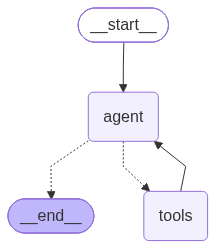

In [11]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))


In [12]:
query = 'What is the capital of India'

messages = {'messages' : [query]}

output = graph.invoke(messages)

In [13]:
output

{'messages': [HumanMessage(content='What is the capital of India', additional_kwargs={}, response_metadata={}, id='f4ae67c6-6fc8-462e-a001-7c5980df8965'),
  AIMessage(content=[{'type': 'text', 'text': 'The capital of India is **New Delhi**.', 'extras': {'signature': 'EsgCCsUCAWkUfRMwbz/kOVgAHznqqV4ZFL625j6lrJIwMFzkbjQDbEu24k9gLhtf1/7/IyEpFoTYwrfJD3Mu0SgiUC9hGbrQrikD9saVht+Z8OVklc0pTWZCJj5S4SdamOvIMB3ysW02FJkU4qKgK0aL0Gif44RxL0acqdkSbRsrJjk5j2ZO15AbMF+qmtW3dX5ntwC3b35Ahduh9QZRpzLw6I/9enuF869L3VkzkSkcH7g47tvcZQbG63QXt3ylSovCky0101H2p+I/d9mSMFlrEH8JTpByd+kjk6agUYhLm7zwWV4NDd5dHfHFWHVdhw1ViXqdIdkIsNaI4oF4VZRm8uygXjI0MFz2vvQx/zVFzOKcmTeqQBQFbVuJTdI16Yr2TWshEfLAr9uD3tphTeWXWGOuje/KXN7dX0ZfSsYshSbO6P86M3SKZQ=='}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.8-flash', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a12039-aaf0-7b61-b0d5-75f916814045-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 7,

In [21]:
ans = output['messages'][-1]

In [23]:
ans = ans.content

In [27]:
ans[0]['text']

'The capital of India is **New Delhi**.'